## Survey Data and Methods

The analysis used 46 survey responses. We summarized self-reported GPA ranges and weekly study time outside class using counts and percentages. To compare GPA distributions across study-time groups, we calculated the percentage in each GPA range within each group.

In [15]:
import sys
print(sys.executable)

import pandas as pd

# Load the cleaned survey data from Part A
survey = pd.read_excel(
    "survey_cleaned_python.xlsx",
    sheet_name="Cleaned Survey"
)

print("Number of responses:", survey.shape[0])
print("Number of columns:", survey.shape[1])

/Users/skymoses/Desktop/CDS3004_Project/clean data/.venv/bin/python
Number of responses: 46
Number of columns: 14


In [16]:
# Count responses in each GPA range
gpa_column = "the range your Gpa grade of last semester"
gpa_counts = survey[gpa_column].value_counts(dropna=False)

# Build the GPA summary table
gpa_summary = gpa_counts.rename_axis("GPA range").to_frame("Count")
gpa_summary["Percentage (%)"] = (gpa_counts / len(survey) * 100).round(1)

display(gpa_summary)

,Count,Percentage (%)
GPA range,,
3.0-3.49,21,45.7
3.5 above,17,37.0
2.5-2.99,5,10.9
below 2.5,3,6.5


You should consider upgrading via the '/Users/skymoses/Desktop/CDS3004_Project/clean data/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


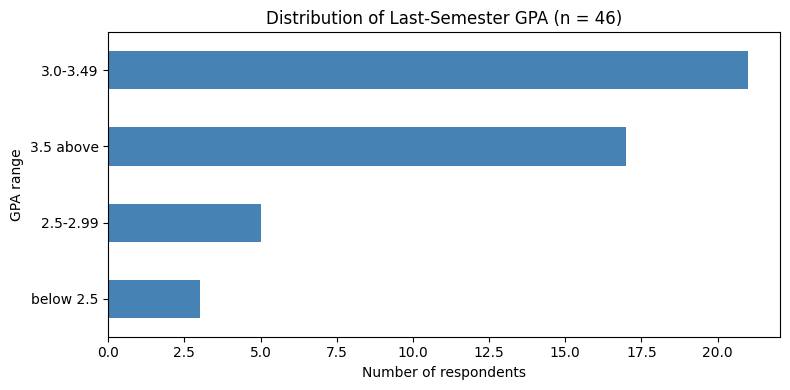

In [17]:
%pip install matplotlib

import matplotlib.pyplot as plt

# Plot the number of respondents in each GPA range
ax = gpa_summary["Count"].plot.barh(figsize=(8, 4), color="steelblue")
ax.invert_yaxis()
ax.set_title("Distribution of Last-Semester GPA (n = 46)")
ax.set_xlabel("Number of respondents")
ax.set_ylabel("GPA range")

plt.tight_layout()
plt.show()

The most common self-reported GPA range was 3.0–3.49, selected by 21 of the 46 respondents (45.7%).

In [18]:
# Summarize weekly study time outside class
study_column = "How much time you spent on studying per week ( outside of class time)"
study_counts = survey[study_column].value_counts(dropna=False)

study_summary = study_counts.rename_axis("Weekly study time").to_frame("Count")
study_summary["Percentage (%)"] = (study_counts / len(survey) * 100).round(1)

display(study_summary)

,Count,Percentage (%)
Weekly study time,,
0-5 hours,12,26.1
6-10 hours,10,21.7
Seldom study beside the Final Exam Period,8,17.4
16-20 hours,6,13.0
21 hours above,5,10.9
11-15 hours,5,10.9


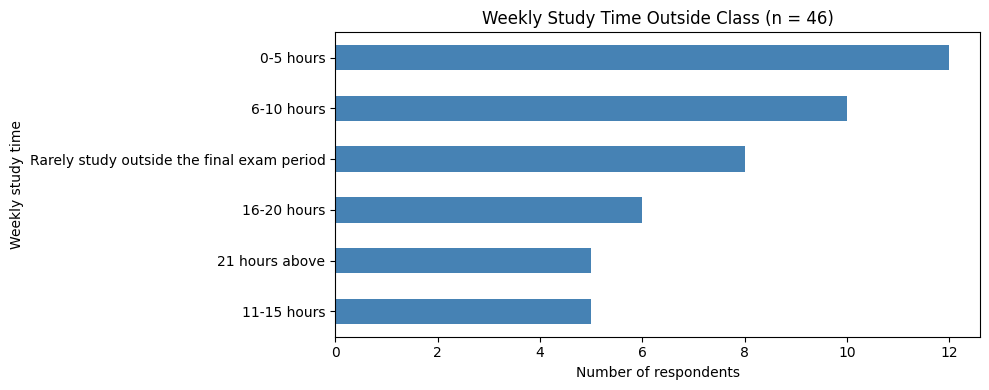

In [19]:
# Shorten the longest label for the chart
study_plot = study_summary["Count"].rename(index={
    "Seldom study beside the Final Exam Period":
        "Rarely study outside the final exam period"
})

# Plot the number of respondents in each study-time category
ax = study_plot.plot.barh(figsize=(10, 4), color="steelblue")
ax.invert_yaxis()
ax.set_title(f"Weekly Study Time Outside Class (n = {len(survey)})")
ax.set_xlabel("Number of respondents")
ax.set_ylabel("Weekly study time")
ax.set_xticks(range(0, int(study_plot.max()) + 1, 2))

plt.tight_layout()
plt.show()

The most common response was 0–5 hours of study outside class per week (12 of 46 respondents, 26.1%). Another 8 respondents (17.4%) reported rarely studying outside the final exam period.

In [20]:
# Count respondents by study-time category and GPA range
study_gpa_counts = pd.crosstab(
    survey[study_column],
    survey[gpa_column],
    rownames=["Weekly study time"],
    colnames=["GPA range"]
)

# Convert counts to percentages within each study-time category
group_sizes = study_gpa_counts.sum(axis=1)
study_gpa_pct = study_gpa_counts.div(group_sizes, axis=0) * 100

print("Respondent counts")
display(study_gpa_counts.assign(Total=group_sizes))

print("Percentage within each study-time category (%)")
display(study_gpa_pct.round(1))

Respondent counts


GPA range,2.5-2.99,3.0-3.49,3.5 above,below 2.5,Total
Weekly study time,,,,,
0-5 hours,2,5,5,0,12
11-15 hours,1,3,1,0,5
16-20 hours,0,2,4,0,6
21 hours above,0,1,3,1,5
6-10 hours,1,4,4,1,10
Seldom study beside the Final Exam Period,1,6,0,1,8


Percentage within each study-time category (%)


GPA range,2.5-2.99,3.0-3.49,3.5 above,below 2.5
Weekly study time,,,,
0-5 hours,16.7,41.7,41.7,0.0
11-15 hours,20.0,60.0,20.0,0.0
16-20 hours,0.0,33.3,66.7,0.0
21 hours above,0.0,20.0,60.0,20.0
6-10 hours,10.0,40.0,40.0,10.0
Seldom study beside the Final Exam Period,12.5,75.0,0.0,12.5


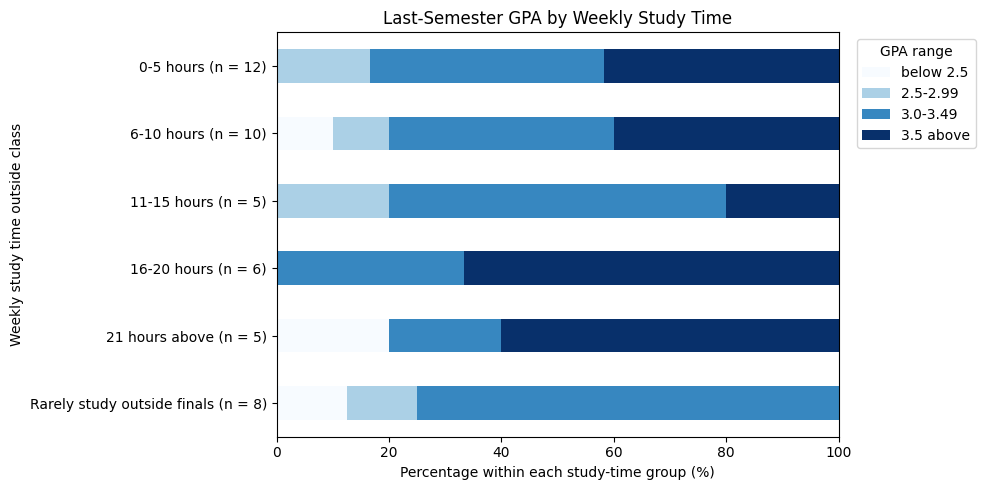

In [21]:
# Order the study-time and GPA categories
study_order = [
    "0-5 hours", "6-10 hours", "11-15 hours",
    "16-20 hours", "21 hours above",
    "Seldom study beside the Final Exam Period"
]
gpa_order = ["below 2.5", "2.5-2.99", "3.0-3.49", "3.5 above"]

chart_data = study_gpa_pct.loc[study_order, gpa_order].copy()

# Add the number of respondents to each group label
chart_data.index = [
    f"{group} (n = {group_sizes[group]})"
    if group != study_order[-1]
    else f"Rarely study outside finals (n = {group_sizes[group]})"
    for group in study_order
]

ax = chart_data.plot.barh(stacked=True, figsize=(10, 5), colormap="Blues")
ax.invert_yaxis()
ax.set_title("Last-Semester GPA by Weekly Study Time")
ax.set_xlabel("Percentage within each study-time group (%)")
ax.set_ylabel("Weekly study time outside class")
ax.set_xlim(0, 100)
ax.legend(title="GPA range", loc="upper left", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

The 16–20 hour group had the highest proportion of respondents in the top GPA category (4 of 6, 66.7%). In the 0–5 hour group, 5 of 12 respondents (41.7%) were in that GPA category. The proportion did not increase consistently across the reported study-hour ranges.

The study-time groups were small, and both GPA and study time were self-reported. These results describe differences within the survey sample and cannot establish whether studying longer leads to a higher GPA.